# TSP — Metaheurísticas

**Optimización DS2011 — fase 4 (sección 3.3 del informe).** Recocido
simulado, algoritmo genético y colonia de hormigas, con los valores de
partida de la guía (todavía sin calibrar — eso es el notebook 5).

Cada celda de parámetros está separada y comentada para poder cambiar un
valor y volver a correr en vivo.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd()
if not (RAIZ / "src" / "tsp").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
from tsp.datos import leer_tsp, matriz_distancias, longitud_ruta
from tsp.heuristicas import vecino_mas_cercano
from tsp.metaheuristicas import calcular_T0, recocido_simulado, genetico, hormigas

inst = leer_tsp(RAIZ / "data" / "raw" / "berlin52.tsp")
D = matriz_distancias(inst.coords)
n = D.shape[0]
OPTIMO = 7542

## 1. Recocido simulado

Acepta mejoras siempre, y empeoramientos con probabilidad `exp(-Δ/T)`. Se
enfría con `T ← alpha_cool·T`. `T0` se calcula para aceptar ~80% de
empeoramientos al inicio.

In [2]:
# parametros (cambiar aqui y volver a correr la celda)
ALPHA_COOL = 0.995
T_MIN = 1e-3
L_ITER = 500
SEMILLA = 0

ruta_inicial = vecino_mas_cercano(D, inicio=0)
T0 = calcular_T0(ruta_inicial, D, semilla=SEMILLA)

mejor_ruta_recocido, costo_recocido, historial_recocido = recocido_simulado(
    ruta_inicial, D, T0=T0, alpha_cool=ALPHA_COOL, T_min=T_MIN, L_iter=L_ITER, semilla=SEMILLA
)
gap_recocido = (costo_recocido - OPTIMO) / OPTIMO * 100
print(f"T0 calculado: {T0:.1f}")
print(f"recocido simulado: L={costo_recocido}  gap={gap_recocido:.2f}%")

T0 calculado: 3696.7
recocido simulado: L=7542  gap=0.00%


## 2. Algoritmo genético

Población de rutas que evoluciona: selección por torneo, cruce OX, mutación
por intercambio o inversión, elitismo.

In [3]:
# parametros (cambiar aqui y volver a correr la celda)
N = 150
P_C = 0.9
P_M = 0.05
G_MAX = 500
E = 3
SEMILLA = 0

mejor_ruta_genetico, costo_genetico, historial_genetico = genetico(
    n, D, N=N, p_c=P_C, p_m=P_M, G_max=G_MAX, e=E, semilla=SEMILLA
)
gap_genetico = (costo_genetico - OPTIMO) / OPTIMO * 100
print(f"genetico: L={costo_genetico}  gap={gap_genetico:.2f}%")

genetico: L=8610  gap=14.16%


## 3. Colonia de hormigas (ACO)

Cada hormiga elige la siguiente ciudad según feromona (τ) y cercanía (η),
con probabilidad ∝ `τ^α · η^β`. Al final de cada ronda se evapora feromona y
se refuerzan las rutas más cortas.

In [4]:
# parametros (cambiar aqui y volver a correr la celda)
M = None  # None -> una hormiga por ciudad
ALPHA = 1
BETA = 3
RHO = 0.3
Q = 100
T_MAX = 100
SEMILLA = 0

mejor_ruta_hormigas, costo_hormigas, historial_hormigas = hormigas(
    n, D, m=M, alpha=ALPHA, beta=BETA, rho=RHO, Q=Q, t_max=T_MAX, semilla=SEMILLA
)
gap_hormigas = (costo_hormigas - OPTIMO) / OPTIMO * 100
print(f"hormigas: L={costo_hormigas}  gap={gap_hormigas:.2f}%")

hormigas: L=7911  gap=4.89%


## Comparación rápida (una sola corrida de cada una)

In [5]:
import pandas as pd

pd.DataFrame([
    {"metodo": "recocido_simulado", "longitud": costo_recocido, "gap_pct": round(gap_recocido, 2)},
    {"metodo": "genetico", "longitud": costo_genetico, "gap_pct": round(gap_genetico, 2)},
    {"metodo": "hormigas", "longitud": costo_hormigas, "gap_pct": round(gap_hormigas, 2)},
]).sort_values("gap_pct")

,metodo,longitud,gap_pct
0,recocido_simulado,7542,0.00
2,hormigas,7911,4.89
1,genetico,8610,14.16


Una sola corrida no alcanza para comparar metaheurísticas estocásticas — con
30 semillas se hace en el notebook 4 (experimentos). Y estos parámetros de
partida todavía no están calibrados: eso es el notebook 5.

## Ruta final del recocido simulado (el mejor de los tres)

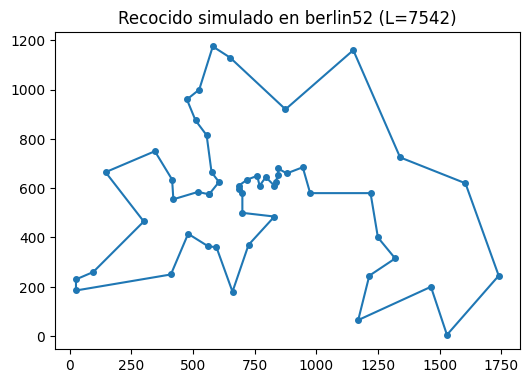

In [6]:
import matplotlib.pyplot as plt

orden = mejor_ruta_recocido + [mejor_ruta_recocido[0]]
xs, ys = inst.coords[orden, 0], inst.coords[orden, 1]

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(xs, ys, "-o", markersize=4, color="C0")
ax.set_title(f"Recocido simulado en berlin52 (L={costo_recocido})")
ax.set_aspect("equal")
plt.show()